<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/8_Object_Detection_using_YOLO_Fruit_image_detection_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics kagglehub
import kagglehub
path = kagglehub.dataset_download('afsananadia/fruits-images-dataset-object-detection')
print(path)

In [ ]:
import os, glob, shutil

# 1. copy images + labels into the folder layout YOLO needs
names = {}
for split, key in (('train', 'Train'), ('val', 'Test')):
    os.makedirs(f'fruits_yolo/images/{split}', exist_ok=True)
    os.makedirs(f'fruits_yolo/labels/{split}', exist_ok=True)
    for txt in glob.glob(f'{path}/{key}*/**/*.txt', recursive=True):
        stem = os.path.splitext(txt)[0]
        img = next((stem + e for e in ('.jpg', '.jpeg', '.png') if os.path.exists(stem + e)), None)
        if img is None: continue
        shutil.copy(img, f'fruits_yolo/images/{split}/')
        shutil.copy(txt, f'fruits_yolo/labels/{split}/')
        cid = int(open(txt).readline().split()[0])
        names[cid] = os.path.basename(stem).split('_', 1)[-1]     # class id -> fruit name from file name

# 2. data.yaml
with open('fruits_yolo/data.yaml', 'w') as f:
    f.write(f"path: {os.path.abspath('fruits_yolo')}\ntrain: images/train\nval: images/val\nnames:\n")
    for i in range(max(names) + 1):
        f.write(f"  {i}: {names.get(i, 'class' + str(i))}\n")
print(open('fruits_yolo/data.yaml').read())

train: 299  val: 77
sample label file:
 0 0.753565 0.580000 0.459130 0.391304
classes: ['Guava']
path: /content/fruits_yolo
train: images/train
val: images/val
names:
  0: Guava



In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')              # small pre-trained YOLOv8 detection model
results = model.train(data=f'{OUT}/data.yaml', epochs=30, imgsz=416, batch=16)

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=fruits_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 899.9±556.0 MB/s, size: 40.3 KB)
val: Scanning /content/fruits_yolo/labels/val.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 21.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.7s/it 18.7s
                   all         77         77      0.357      0.605      0.408      0.253
Speed: 0.6ms preprocess, 143.1ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/runs/detect/val
mAP@0.5: 0.40794882344927597   mAP@0.5:0.95: 0.25348044532541475


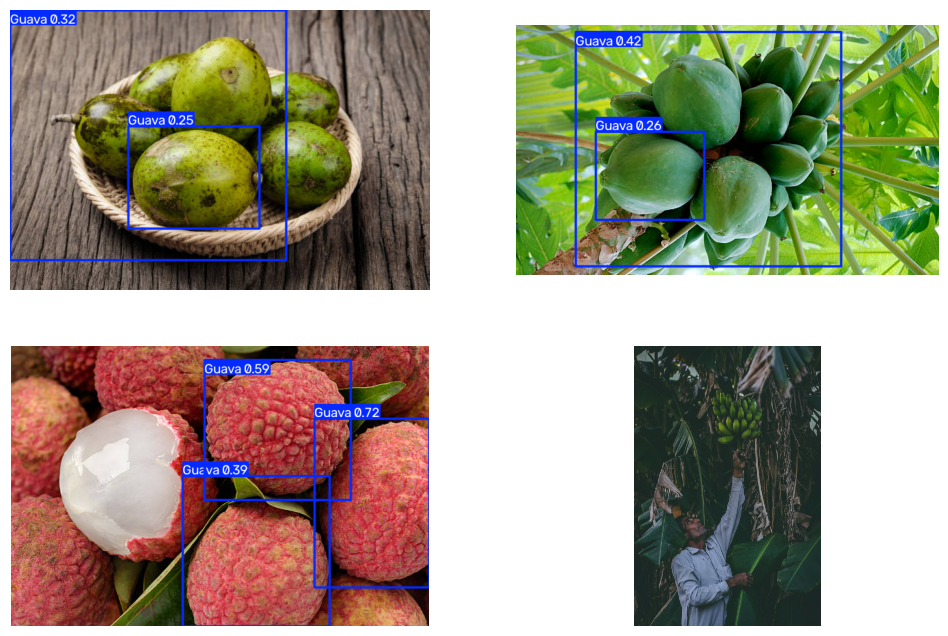

In [ ]:
# Evaluate: mAP = main detection metric
metrics = model.val()
print("mAP@0.5:", metrics.box.map50, "  mAP@0.5:0.95:", metrics.box.map)

# Detect fruits in some validation images (boxes + class + confidence)
val_imgs = glob.glob(f'{OUT}/images/val/*')
plt.figure(figsize=(12, 8))
for i, f in enumerate(random.sample(val_imgs, min(4, len(val_imgs)))):
    r = model.predict(f, conf=0.25, verbose=False)[0]
    plt.subplot(2, 2, i + 1); plt.imshow(r.plot()[..., ::-1]); plt.axis('off')     # r.plot() is BGR -> flip to RGB
plt.show()

In [ ]:
1. What is the problem?

Given a photo containing fruit, the computer must find where each fruit is, draw a box around it, and say which fruit it is, with a confidence score. This is real object detection, unlike Problem 7.

2. The dataset (your actual copy)

When we checked the files, your copy has:

400 images in two folders: Train File (about 320 images) and Test File (about 80 images).
A .txt label file for every image, with the same name (for example 40_Grapes.jpg and 40_Grapes.txt).
Many kinds of fruit, such as grapes, guava, mango, litchi, papaya, banana, orange and jackfruit.

Each .txt file is in YOLO label format. Each line describes one fruit box:

class_id x_center y_center width height

All values after the class id are between 0 and 1, as fractions of the image size.
Example: 3 0.52 0.48 0.30 0.35 means class 3, centred just right of the middle, covering 30% of the width and 35% of the height.

3. What is the solution?

We use YOLOv8 in detection mode (yolov8n.pt), pre-trained on the COCO dataset, and fine-tune it on our fruit images. This is transfer learning again.

YOLOv8 detection architecture (a good thing to draw):

Part	What it does (simple words)
Backbone	Looks at the image and extracts features (Conv layers + C2f blocks + SPPF).
Neck (PAN-FPN)	Mixes features from three scales, so it can spot small, medium and large fruits.
Head (decoupled)	One branch predicts the box (x, y, w, h). A second branch predicts the class (which fruit). It is anchor-free: it predicts boxes directly with no pre-set box shapes.
NMS	Non-Maximum Suppression removes duplicate boxes, so each fruit gets one box.

Flow: Image → Backbone → Neck → Head (box + class) → NMS → boxes with labels and confidence.

Key terms:

Bounding box: the rectangle around an object.
Confidence: how sure the model is, from 0 to 1.
IoU (Intersection over Union): how much a predicted box overlaps the true box. IoU = overlap area ÷ combined area. 1 is perfect and 0 is no overlap.
NMS: keeps the best box and deletes other boxes that overlap it too much.
mAP (mean Average Precision): the main detection score. mAP@0.5 counts a box as correct if IoU is at least 0.5. mAP@0.5:0.95 is a stricter average over many IoU thresholds.
#################### The code, explained

Step 1: Install and download

python
!pip -q install ultralytics kagglehub
path = kagglehub.dataset_download('afsananadia/fruits-images-dataset-object-detection')

Step 2: Pair images with labels and build the YOLO folders (the replacement cell I gave you)

python
train_pairs, val_pairs = pairs_in('train'), pairs_in('test')
It matches each image with the .txt file of the same name. Train File becomes training data and Test File becomes validation data.
It checks the label numbers are between 0 and 1 (proving they're YOLO format).
It reads the class names from the file names (40_Grapes.jpg gives class "Grapes"), because the dataset has no class list file.
It copies everything into the folder structure YOLO needs:
fruits_yolo/images/train, images/val
fruits_yolo/labels/train, labels/val
It writes data.yaml, a small config file with the dataset path and the class names. YOLO reads this to know where the data is.

Step 3: Train

python
from ultralytics import YOLO
model = YOLO('yolov8n.pt')
results = model.train(data='fruits_yolo/data.yaml', epochs=30, imgsz=416, batch=16)
yolov8n.pt: the small pre-trained detection model.
imgsz=416: images are resized to 416×416.
epochs=30: 30 passes. (On CPU use 2 just for testing.)

Step 4: Evaluate and detect

python
metrics = model.val()
print("mAP@0.5:", metrics.box.map50, "mAP@0.5:0.95:", metrics.box.map)
r = model.predict(f, conf=0.25)[0]
plt.imshow(r.plot()[..., ::-1])
model.val() computes precision, recall and mAP.
conf=0.25 hides boxes under 25% confidence.
r.plot() draws the boxes and labels on the image, and [..., ::-1] flips the colour order from BGR to RGB for display.
5. The output you will see
train: 320 | val: 80, then the printed classes: list. Check this looks like fruit names.
The data.yaml text.
Ultralytics prints the model summary and then a training table for each epoch, with losses (box_loss, cls_loss, dfl_loss) decreasing and mAP50 rising.
Results saved in runs/detect/train (including best.pt, results.png and a confusion matrix).
Final mAP@0.5. A number around 0.5–0.9 is plausible, but I haven't run it on your real dataset, so go by your own result.
Four fruit images with coloured boxes, labels and confidence, such as Grapes 0.87.
6. What to tell the examiner (30-second version)

"YOLO is a single-stage detector that predicts boxes and classes in one pass. I used YOLOv8 nano, pre-trained on COCO. The dataset has images with YOLO-format label files, so I paired images and labels, made the images/labels train and validation folders, and wrote a data.yaml file with the class names. I fine-tuned the model for 30 epochs at 416×416 and evaluated with mAP. For prediction, the model draws a box, a class label and a confidence for each fruit, and NMS removes duplicate boxes."
####################BLOCK
          START
            |
            v
      Load Fruit Dataset
            |
            v
      Read XML Annotations
            |
            v
      Convert XML to TXT
       (YOLO Format)
            |
            v
      Prepare Dataset
       Train / Validation
            |
            v
      Load YOLOv8 Model
        (yolov8n.pt)
            |
            v
        Train Detector
            |
            v
       Validate Model
            |
            v
      Calculate mAP
            |
            v
      Detect Fruit Objects
            |
            v
     Draw Bounding Boxes
            |
            v
           STOP



################################Questions the examiner may ask
Explain the YOLOv8 architecture. Backbone extracts features, the neck merges three scales, and the decoupled head predicts boxes and classes separately. It is anchor-free.
What is the YOLO label format? One line per object: class x_center y_center width height, all normalised between 0 and 1.
What is IoU? Overlap area divided by union area of the predicted and true box.
What is NMS? It keeps the highest-confidence box and removes others that overlap it above a threshold.
What is mAP? The mean of the average precision over all classes. mAP@0.5 uses an IoU threshold of 0.5.
What is anchor-free? Older YOLO versions used pre-defined anchor box shapes. YOLOv8 predicts the box directly.
What is data.yaml? A config file listing the dataset path, the train and val folders, and the class names.
What is a confidence threshold? Boxes below it (0.25 here) are discarded.
YOLO vs R-CNN? R-CNN is two-stage (propose regions, then classify), which is accurate but slow. YOLO is one-stage and much faster.